In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import pandas as pd

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

#plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-ticks')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])

from trips.utilities.weights import smoothed_holder_weights


from msolver import IASGKS, MMGKS, VanillaGKS, MM2019GKS
from fsolver import IASFGK, MMFGK, MM2019FGK # VanillaFK
from pgkbsolver import MMGKB, IASGKB, MM2019GKB
from f2019solver import MM2019FGK2019, IASFGK2019


# Setup the problem data

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)
ground_truth -= 5.5
ground_truth *= -1

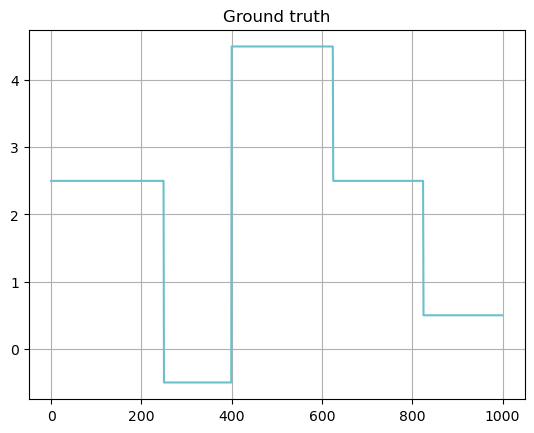

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


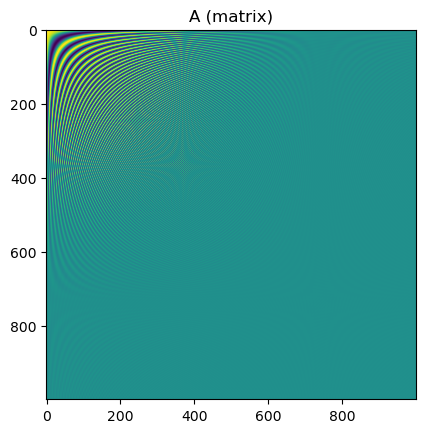

In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [6]:
# Only first 50 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

In [7]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

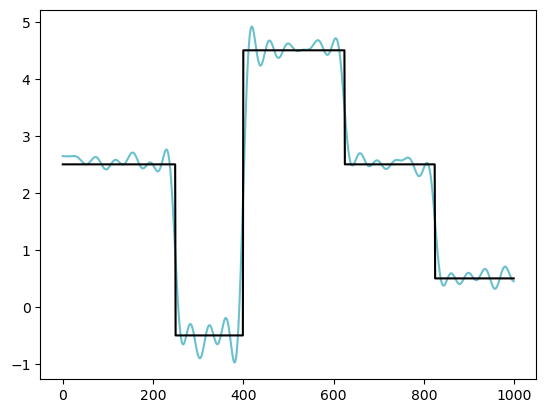

In [8]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [9]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
K = None
xker = None

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))


mmgks_weight_params2019 = {
    "q": 1.0,
    "tau1": 1e-10,
    "tau2": 1e-16,
}

iasgks_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}


# Setup solvers

In [10]:
# Vanilla GKS
v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

# MM weights (always using 2019 version)
mm_gks_solver = MM2019GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mm_fgk_solver = MM2019FGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mm_fgk2019_solver = MM2019FGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K)
mm_psgkb_solver = MM2019GKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

# IAS weights
ias_gks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
ias_fgk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
ias_fgk2019_solver = IASFGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K)
ias_psgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

# Solve using all methods

In [11]:
# Parameters
method = "dp"
n_its = 125
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7

In [15]:
%%capture 

### MM weights (2019 version)

all_v_results = []

# Vanilla GKS
v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)

all_v_results.append( ( "V", "GKS", v_gks_data  ) )


all_mm_results = []

# S-GKS
mm_sgks_data = mm_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)

all_mm_results.append( ( "MM", "S-GKS", mm_sgks_data  ) )



# Recycled/restarted S-GKS
mm_sgks_resdata = mm_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=mmgks_weight_params2019,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)


mm_sgks_recdata = mm_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)


# PS-GKS
mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019, 
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS", mm_psgks_data  ) )


mm_psgkb_data = mm_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "PS-GKB", mm_psgkb_data  ) )


# FGK
mm_fgk_data = mm_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )

all_mm_results.append( ( "MM", "FGK", mm_fgk_data  ) )



# FGK2019 (there are four versions to do here.)
mm_fgk2019I_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FLSQR-I", mm_fgk2019I_data  ) )


mm_fgk2019R_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FLSQR-R", mm_fgk2019R_data  ) )

mm_fgk2019W_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FLSQR-W", mm_fgk2019W_data  ) )

mm_fgk2019IRW_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "IRW-FLSQR", mm_fgk2019IRW_data  ) )


In [23]:
%%capture 

### IAS weights


all_ias_results = []

# S-GKS
ias_sgks_data = ias_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)

all_ias_results.append( ( "IAS", "S-GKS", ias_sgks_data  ) )



# Recycled/restarted S-GKS
ias_sgks_resdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)


ias_sgks_recdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)


# PS-GKS
ias_psgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS", ias_psgks_data  ) )


ias_psgkb_data = ias_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "PS-GKB", ias_psgkb_data  ) )


# FGK
ias_fgk_data = ias_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )

all_ias_results.append( ( "IAS", "FGK", ias_fgk_data  ) )



# FGK2019 (there are four versions to do here.)
ias_fgk2019I_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FLSQR-I", ias_fgk2019I_data  ) )


ias_fgk2019R_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FLSQR-R", ias_fgk2019R_data  ) )

ias_fgk2019W_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FLSQR-W", mm_fgk2019W_data  ) )

ias_fgk2019IRW_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "IRW-FLSQR", ias_fgk2019IRW_data  ) )


# Save and make tables

In [29]:
v_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_v_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ]})
        v_df = pd.concat([v_df, new_df], axis=0)


mm_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_mm_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ]})
        mm_df = pd.concat([mm_df, new_df], axis=0)



ias_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_ias_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ]})
        ias_df = pd.concat([ias_df, new_df], axis=0)



        
# mm

#                        "noise_var":[], "n_cgls":[], "n_pcgls":[], "wallclock_ratio":[], "relerr":[], "ssim":[], "phi": [] })

In [38]:
all_df = pd.concat([v_df, mm_df, ias_df])
all_df = all_df.rename(columns={'lambdah': '$\lambda$'})
all_df

,Weights,Method,$\lambda$,RRE,SSIM,Gini index,Hoyer index
0,V,GKS,1.870527e+02,0.112441,0.913804,0.668519,0.525278
0,MM,S-GKS,2.316871e+01,0.098861,0.935470,0.835968,0.679823
0,MM,PS-GKS,5.701229e+01,0.061600,0.968819,0.968178,0.859036
0,MM,PS-GKB,5.716651e+01,0.064564,0.966714,0.969252,0.861952
0,MM,FGK,3.531511e+01,0.085363,0.949222,0.928529,0.766735
0,MM,FLSQR-I,2.704394e+00,0.095625,0.926998,0.789035,0.641355
0,MM,FLSQR-R,1.574409e+02,0.104410,0.928233,0.778379,0.625357
0,MM,FLSQR-W,1.535302e+01,0.099428,0.934408,0.855182,0.676332
0,MM,IRW-FLSQR,4.085204e+01,0.079677,0.954191,0.928372,0.777225
0,IAS,S-GKS,3.210433e+02,0.086322,0.956970,0.799044,0.928958


In [39]:
def scientific_to_latex(sci_str):
    # Split the number into base and exponent parts
    sci_str = f"{sci_str:.0e}"
    base, exponent = sci_str.split('e')
    
    # Convert base to integer (since the decimal places can be ignored)
    base = str(int(float(base)))
    
    # Prepare the exponent part, removing the leading "+" if it's a positive exponent
    exponent = exponent.lstrip("+")
    
    # Format the result as a LaTeX string
    latex_str = f"${base}\\cdot10^{{{int(exponent)}}}$"
    
    return latex_str

In [40]:
print( all_df.to_latex(index=False, formatters={'$\lambda$': lambda s: scientific_to_latex(s), 
                                                "RRE": "${:.3f}$", "SSIM": "${:.3f}$", 
                                                  "Gini index": "${:.3f}$", "Hoyer index": "${:.3f}$"
                                                    }) )

\begin{tabular}{llrrrrr}
\toprule
Weights & Method & $\lambda$ & RRE & SSIM & Gini index & Hoyer index \\
\midrule
V & GKS & $2\cdot10^{2}$ & $0.112$ & $0.914$ & $0.669$ & $0.525$ \\
MM & S-GKS & $2\cdot10^{1}$ & $0.099$ & $0.935$ & $0.836$ & $0.680$ \\
MM & PS-GKS & $6\cdot10^{1}$ & $0.062$ & $0.969$ & $0.968$ & $0.859$ \\
MM & PS-GKB & $6\cdot10^{1}$ & $0.065$ & $0.967$ & $0.969$ & $0.862$ \\
MM & FGK & $4\cdot10^{1}$ & $0.085$ & $0.949$ & $0.929$ & $0.767$ \\
MM & FLSQR-I & $3\cdot10^{0}$ & $0.096$ & $0.927$ & $0.789$ & $0.641$ \\
MM & FLSQR-R & $2\cdot10^{2}$ & $0.104$ & $0.928$ & $0.778$ & $0.625$ \\
MM & FLSQR-W & $2\cdot10^{1}$ & $0.099$ & $0.934$ & $0.855$ & $0.676$ \\
MM & IRW-FLSQR & $4\cdot10^{1}$ & $0.080$ & $0.954$ & $0.928$ & $0.777$ \\
IAS & S-GKS & $3\cdot10^{2}$ & $0.086$ & $0.957$ & $0.799$ & $0.929$ \\
IAS & PS-GKS & $1\cdot10^{7}$ & $0.049$ & $0.985$ & $0.997$ & $0.970$ \\
IAS & PS-GKB & $1\cdot10^{7}$ & $0.049$ & $0.985$ & $0.997$ & $0.970$ \\
IAS & FGK & $5\cdot10

# Test

# Plotting setup